# Support Vector Machines and Kernels

![SVM.png](./Assets/SVM.png)

# Цели обучения
- Применить метод опорных векторов (SVM) — популярный алгоритм, используемый для задач классификации
- Распознать сходство SVM с логистической регрессией
- Вычислить функцию потерь для SVM
- Применить регуляризацию в SVM и изучить советы по получению нелинейной классификации с помощью SVM

## Введение
В этих упражнениях мы будем использовать набор данных о качестве вина. Этот набор данных содержит различные химические свойства вина, такие как кислотность, сахар, pH и алкоголь. Он также содержит метрику качества (от 3 до 9, где наивысший балл означает лучшее качество) и цвет (красное или белое). Имя файла: `Wine_Quality_Data.csv`.

In [64]:
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.svm import LinearSVC
from sklearn.svm import SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.svm import SVC
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import MinMaxScaler

from sklearnex import patch_sklearn
patch_sklearn()

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1
* Импорт данных.
* Создайте целевую переменную `y` как колонка 1/0, где 1 означает красное вино.
* Создайте парный график для набора данных.
* Создайте диаграмму столбцов, которая отображает корреляцию между каждым колонкой и `y`.
* Выберите 2 поля с наибольшей корреляцией (используя значения абсолютной корреляции) и создайте `X`.
* Используйте MinMaxScaler для масштабирования `X` Обратите внимание, что вывод будет np.array. Сделайте его снова DataFrame и соответственно переименуйте столбцы.

color
white    4898
red      1599
Name: count, dtype: int64


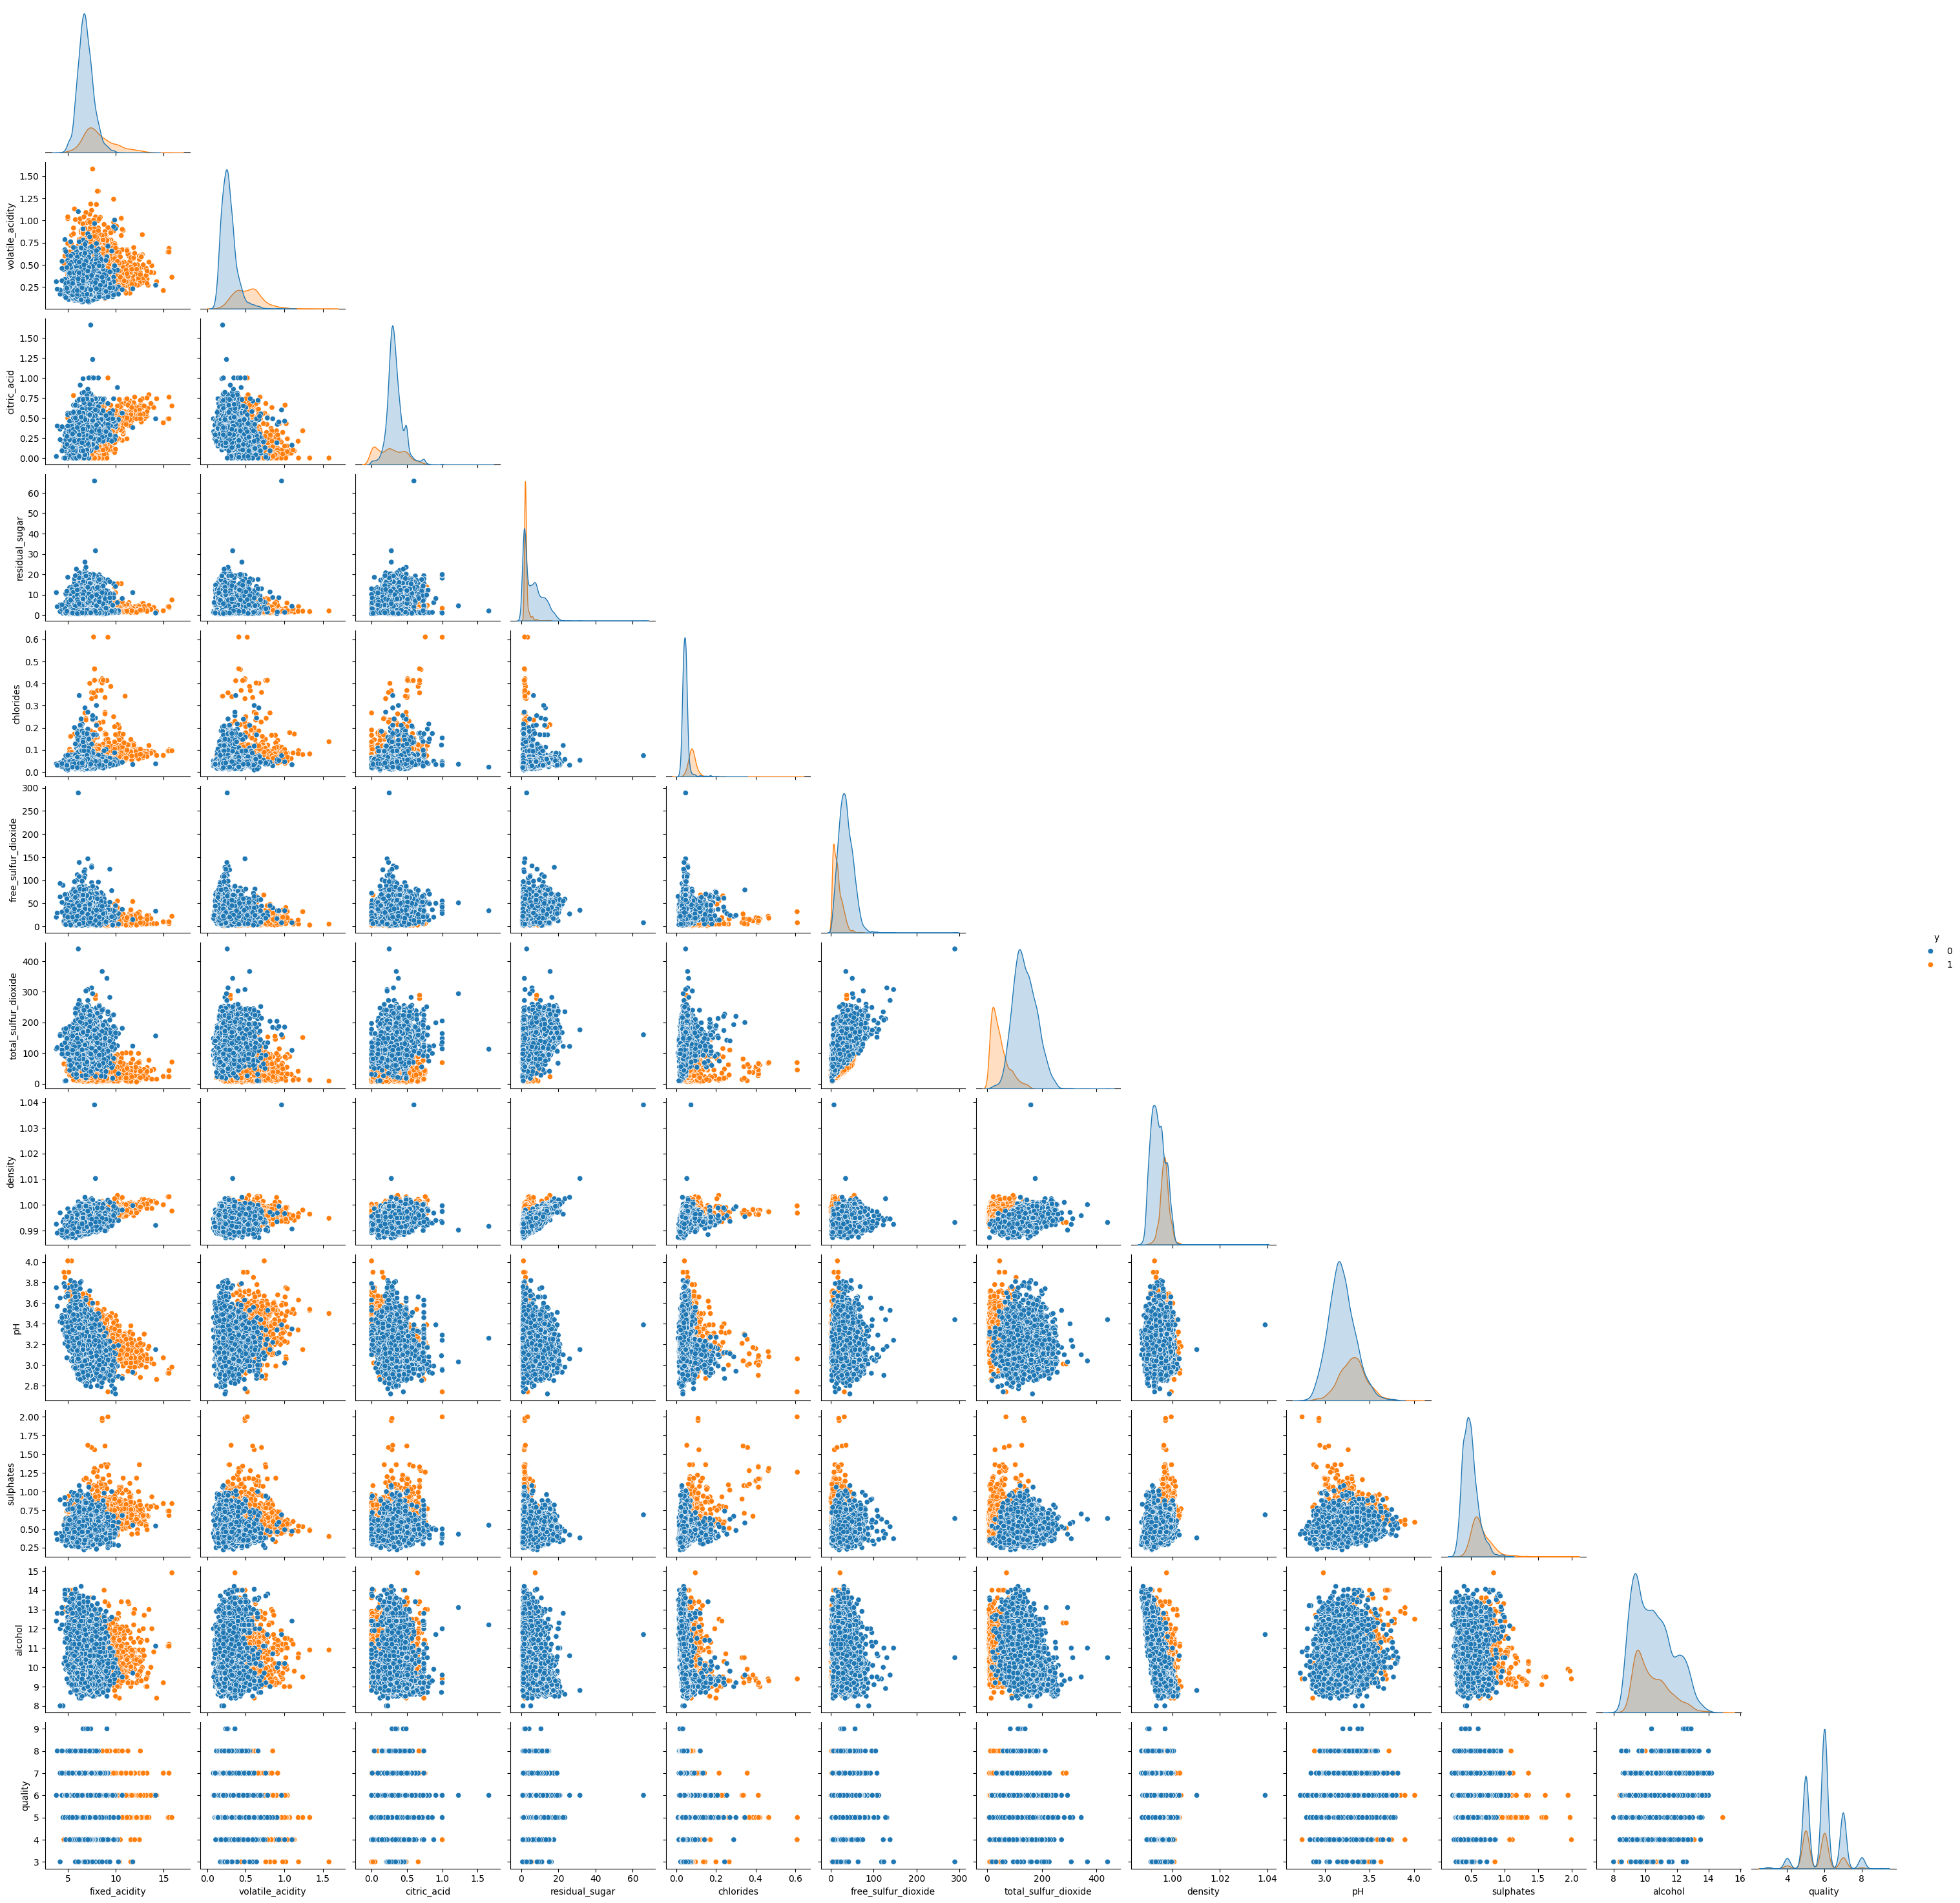

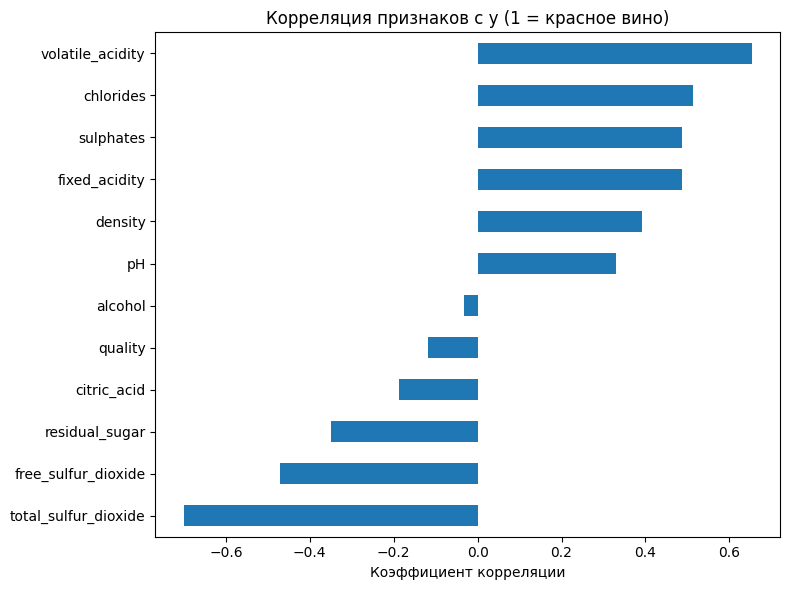

Признаки ['total_sulfur_dioxide', 'volatile_acidity']
   total_sulfur_dioxide  volatile_acidity
0                  34.0              0.70
1                  67.0              0.88
2                  54.0              0.76
3                  60.0              0.28
4                  34.0              0.70
     total_sulfur_dioxide  volatile_acidity
min                   6.0              0.08
max                 440.0              1.58


In [65]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler 

wineList = pd.read_csv('./data/Wine_Quality_Data.csv')

print(wineList['color'].value_counts())
y = (wineList['color'] == 'red').astype(int)

dropColumn = wineList.drop(columns="color")
pair = dropColumn.copy()
pair["y"] = y
sns.pairplot(pair, hue='y', corner=True)
plt.show()


corr_y = dropColumn.corrwith(y).sort_values()

plt.figure(figsize=(8,6))
corr_y.plot(kind='barh')
plt.title("Корреляция признаков с y (1 = красное вино)")
plt.xlabel("Коэффициент корреляции")
plt.tight_layout()
plt.show()

top = corr_y.abs().sort_values(ascending=False).head(2).index.tolist()
print('Признаки', top)
X = dropColumn[top]

scaler = MinMaxScaler()
x_scale = scaler.fit_transform(X)
x = pd.DataFrame(x_scale, columns=top, index=X.index)

print(X.head())
print(X.describe().loc[["min","max"]])

## Вопрос 2

Цель этого вопроса - посмотреть на границу принятия решения классификатора LinearSVC для данного набора данных. Ознакомьтесь с [этим примером](http://scikit-learn.org/stable/auto_examples/svm/plot_iris.html#sphx-glr-auto-examples-svm-plot-iris-py) в документации sklearn. 

* Установите классификатор линейной векторной машины поддержки на `X` , `y`.
* Выберите 300 образцов из `X`. Получите соответствующее значение `y`. Сохраните их в переменных `X_color` и `y_color`. Это связано с тем, что оригинальный набор данных слишком велик и создает переполненный график.
* Измените `y_color` таким образом, чтобы вместо 1 было указано значение «красный», а вместо 0 - «желтый».
* Рассеянный график для столбцов X_color. Используйте аргумент ключевого слова "color=y_color" для отображения кода цвета.
* Используйте фрагмент кода ниже, чтобы нарисовать поверхность решения в цветной форме.

`python
x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel]). T
y_grid_predictions = *[ВАША МОДЕЛЬ]*. predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)
ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
`

Не стесняйтесь экспериментировать с различными вариантами параметров для LinearSVC и просмотреть границы принятия решения.

Точность обучения: 0.95474834539018


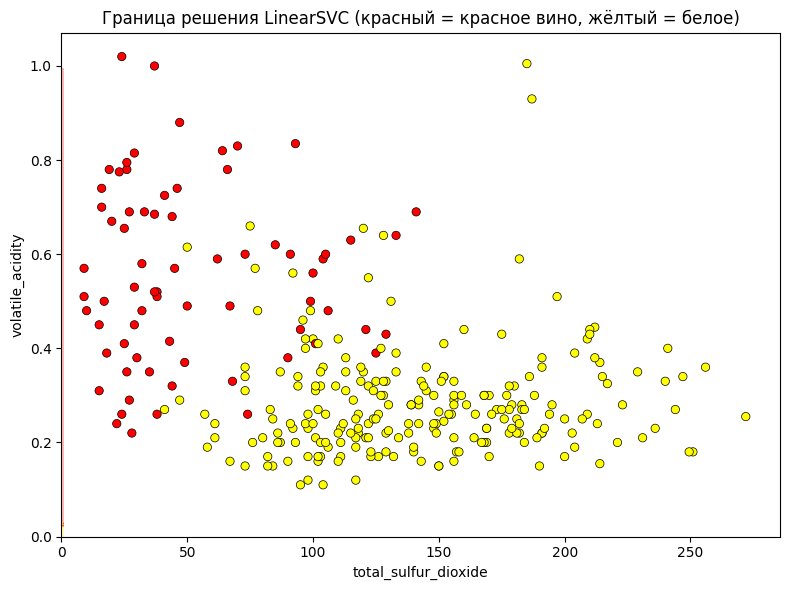

In [66]:
from sklearn.svm import LinearSVC


model = LinearSVC(C=1.0, max_iter=10000, random_state=42)
model.fit(X, y)
print("Точность обучения:", model.score(X, y))


X_color = X.sample(300, random_state=42)
y_color = y.loc[X_color.index]

y_color = y_color.map({1: "red", 0: "yellow"})

fig, ax = plt.subplots(figsize=(8, 6))
 
ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1],
           color=y_color, edgecolor="k", linewidth=0.5)
 
x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel]).T
X_grid.columns = X.columns 
y_grid_predictions = model.predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)
ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
 
ax.set_xlabel(X.columns[0])
ax.set_ylabel(X.columns[1])
ax.set_title("Граница решения LinearSVC (красный = красное вино, жёлтый = белое)")
plt.tight_layout()
plt.savefig("decision_boundary.png", dpi=120)
plt.show()

## Вопрос 3

Давайте теперь развернем гауссовское ядро SVC и посмотрим, как изменяется граница решения.

* Объедините фрагменты кода в вопросе 2 в одну функцию, которая использует оценщика `X` и `y`, и создаст окончательный график с границей решения. Этапы:
    <ol>
     <li> подходящая модель
     <li> получить выборку 300 записей из X и соответствующих у
     <li> создать сетку, предсказать, составить график с помощью ax.contourf
     <li> добавить на рассеянный график
    </ol>
* После копирования и вставки кода убедитесь, что готовая функция использует ваш входной `оценщик` а не созданную вами модель LinearSVC.
* Для следующих значений `gamma` создайте Gaussian Kernel SVC и нарисуйте границу решения.  
`gammas = [.5, 1, 2, 10]`
* Удерживая `gamma` постоянную, для различных значений `C`, нарисуйте границу решения. Вы можете попробовать  
`Cs = [.1, 1, 10]>

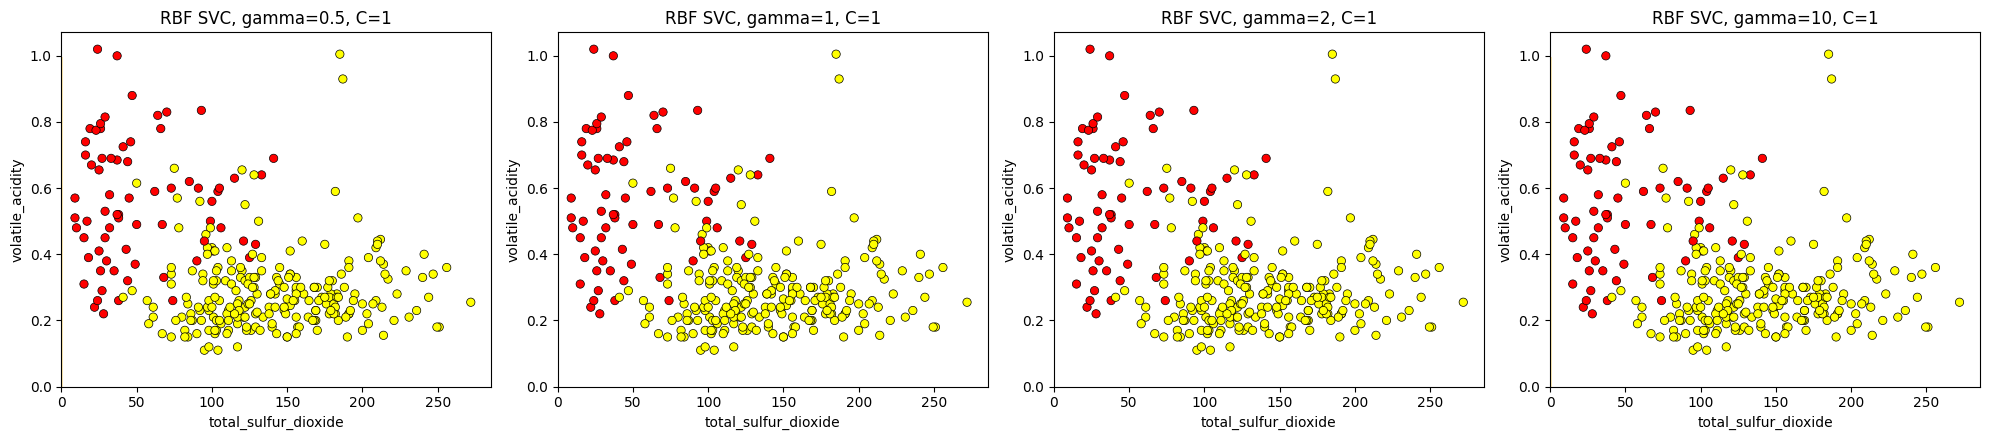

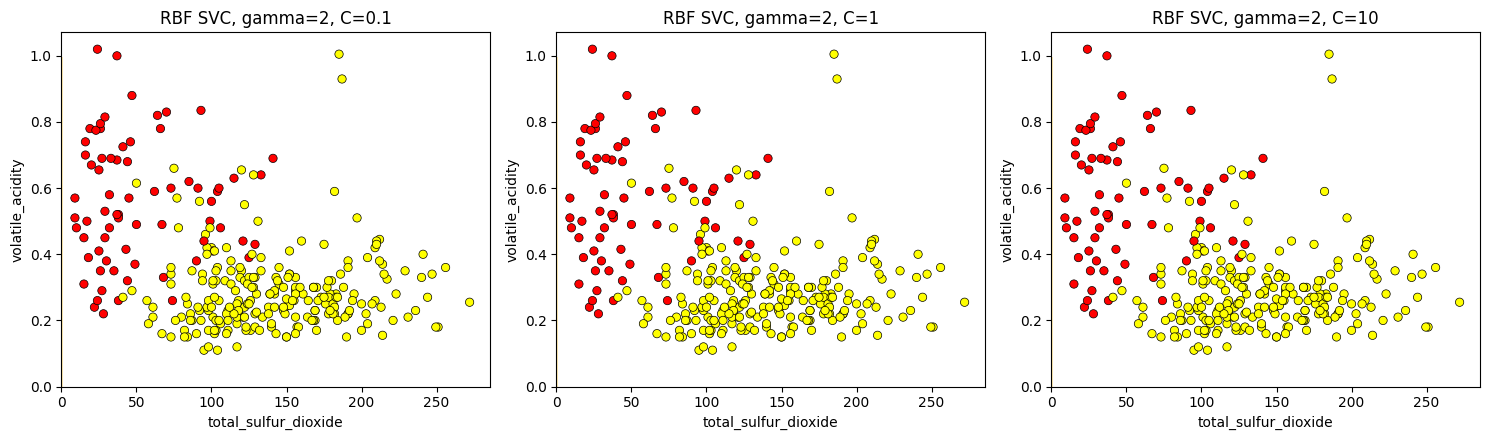

In [67]:
def plot_decision_boundary(estimator, X, y, ax=None, title=None):
    estimator.fit(X, y)
 
    X_color = X.sample(300, random_state=42)
    y_color = y.loc[X_color.index].map({1: "red", 0: "yellow"})
 
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
 
    x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
    xx, yy = np.meshgrid(x_axis, y_axis)
    X_grid = pd.DataFrame([xx.ravel(), yy.ravel()]).T
    X_grid.columns = X.columns
    y_grid_predictions = estimator.predict(X_grid).reshape(xx.shape)
    ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
 
    ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1],
               color=y_color, edgecolor="k", linewidth=0.5)
 
    ax.set_xlabel(X.columns[0])
    ax.set_ylabel(X.columns[1])
    if title:
        ax.set_title(title)
    return ax


gammas = [.5, 1, 2, 10]

fig, axes = plt.subplots(1, len(gammas), figsize=(5 * len(gammas), 4.5))
for ax, gamma in zip(axes, gammas):
    plot_decision_boundary(SVC(kernel="rbf", gamma=gamma, C=1), X, y,
                           ax=ax, title=f"RBF SVC, gamma={gamma}, C=1")
plt.tight_layout()
plt.savefig("decision_boundary_gammas.png", dpi=110)
plt.show()


Cs = [.1, 1, 10]
fig, axes = plt.subplots(1, len(Cs), figsize=(5 * len(Cs), 4.5))
for ax, C in zip(axes, Cs):
    plot_decision_boundary(SVC(kernel="rbf", gamma=2, C=C), X, y,
                           ax=ax, title=f"RBF SVC, gamma=2, C={C}")
plt.tight_layout()
plt.savefig("decision_boundary_Cs.png", dpi=110)
plt.show()

## Вопрос 4

В этом вопросе мы сравним время установки между SVC и Nystroem с ядром rbf.  
<br><br>
Jupyter Notebooks предоставляет полезную магическую функцию **`%timeit`** которая выполняет строку и отпечатывает время, необходимое для установки. Если вы введете **`%timeit`** в начале ячейки, то она запустит всю ячейку и отобразит время выполнения.

* Повторно загрузите данные о качестве вина, если вы внесли изменения в оригинал.
* Создайте `y` из data.color и `X` из остальных столбцов.
* Используйте `%%timeit` чтобы получить время для настройки SVC с ядром rbf.
* Используйте `%%timeit` для получения времени для следующего: упорядочите данные с помощью Nystroem, а затем встроите SGD-классификатор.

Nystroem+SGD потребуется гораздо меньше времени для установки. Эта разница будет более выраженной, если набор данных был больше.

* Сделайте 5 копий X и свяжите их
* Сделайте 5 копий у и свяжите их
* Сравните время, необходимое для соответствия обоим методам выше.

In [68]:
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDClassifier

data = pd.read_csv('./data/Wine_Quality_Data.csv')
y = (data['color'])
X = data.drop(columns="color")

X = pd.DataFrame(MinMaxScaler().fit_transform(X), columns=X.columns)

print(X.shape, y.shape)


(6497, 12) (6497,)


In [69]:
%%timeit
svc = SVC(kernel="rbf", gamma=.5)
svc.fit(X, y)

205 ms ± 3.81 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [70]:
%%timeit
kernel_approx = Nystroem(kernel="rbf", gamma=.5, n_components=100, random_state=42)
X_transformed = kernel_approx.fit_transform(X)
sgd = SGDClassifier(max_iter=1000, tol=1e-3, random_state=42)
sgd.fit(X_transformed, y)

63.3 ms ± 3.18 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [71]:
X_big = pd.concat([X] * 5, ignore_index=True)
y_big = pd.concat([y] * 5, ignore_index=True)
print(X_big.shape, y_big.shape)

(32485, 12) (32485,)


In [72]:
%%timeit
svc = SVC(kernel="rbf", gamma=.5)
svc.fit(X_big, y_big)

838 ms ± 46.1 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [73]:
%%timeit
kernel_approx = Nystroem(kernel="rbf", gamma=.5, n_components=100, random_state=42)
X_transformed = kernel_approx.fit_transform(X_big)
sgd = SGDClassifier(max_iter=1000, tol=1e-3, random_state=42)
sgd.fit(X_transformed, y_big)

228 ms ± 5.51 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
